[saved] results\tables\tab_floor_sensitivity.csv
[saved] results\tables\tab_floor_sensitivity.tex
[saved] results\tables\tab_override_summary.csv
[saved] results\tables\tab_override_summary.tex
== R7: override descriptive stats (current fit) ==
               metric    value
               n_rows 1219.000
              n_firms  361.000
   residual_scale_mad    0.965
     band_coverage_80    0.765
       n_outside_band  287.000
adopted_floor_1.5xMAD    1.450
override_rows_adopted  114.000
 tau  overrides  rate_pct
1.40        119       9.8
1.45        114       9.4
2.00         43       3.5
-> paste these into the data section (MAD, coverage, n_outside) and the appendix floor table; they now match the override count used in analysis.

== R3: P2 proxy-metric diagnosis (offline) ==
mean metric drop on P2 (x5): 0.548
mean chars removed by P2    : 426
corr(metric drop, chars removed): Spearman rho=-0.023 (p=0.781)
[saved] results\figures\fig_p2_metric_diagnosis.png
[saved] results\figures\f

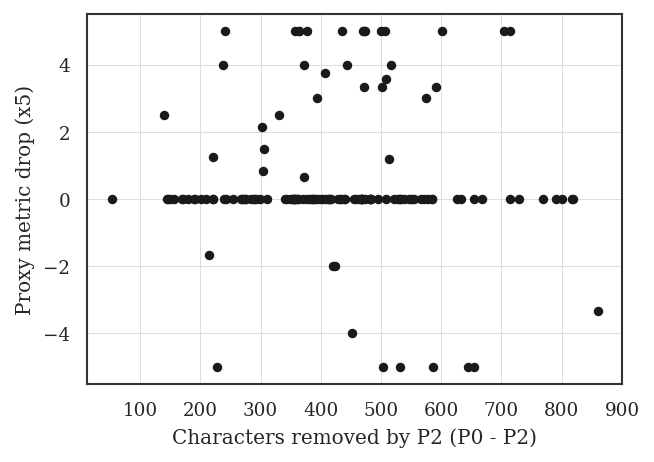


claim-count decomposition (P0 vs P2):
pert  mean_total  mean_ratio
  P0    7.157895    0.282817
  P2    5.815789    0.149102
[saved] results\tables\tab_p2_metric_diagnosis.csv
[saved] results\tables\tab_p2_metric_diagnosis.tex
Interpretation guide: a large positive corr with chars-removed, and/or a drop in mean_total with a stable ratio, indicates the P2 'metric drop' is a claim-count/length artifact rather than a genuine faithfulness change.
[saved] results\tables\tab_p4b_notch_sensitivity.csv
[saved] results\tables\tab_p4b_notch_sensitivity.tex

== R4: P4b sensitivity to grade-move magnitude ==
 construct_notch grade_view   n  judge_drop   d_z
               1      shown 144       2.215 1.529
               1     hidden 144       2.090 1.484
               2      shown 144       2.236 1.554
               2     hidden 144       2.083 1.508
               3      shown 144       2.333 1.704
               3     hidden 144       2.097 1.513
[saved] results\figures\fig_p4b_notch_sensiti

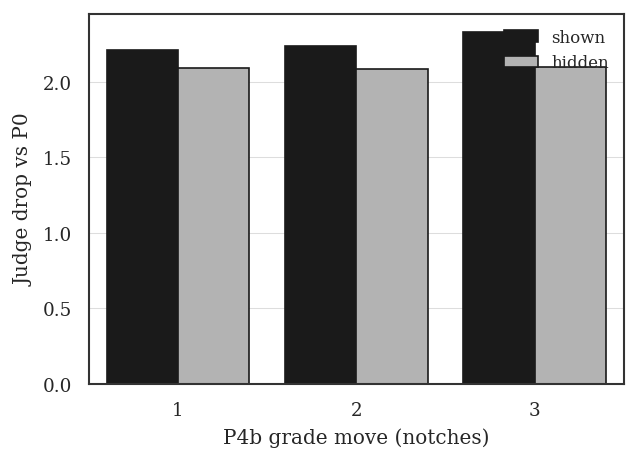

[saved] results\tables\tab_multiseed_p4.csv
[saved] results\tables\tab_multiseed_p4.tex

== R6: P4 effect stability across seeds ==
 seed  n  p4_judge_drop   d_z
    0 40          2.150 1.615
    1 40          1.975 1.338
    2 40          2.075 1.360
    3 40          2.050 1.510
    4 40          2.175 1.603
d_z across seeds: mean=1.485, sd=0.131, range=[1.338, 1.615]
[saved] results\figures\fig_multiseed_p4.png
[saved] results\figures\fig_multiseed_p4.pdf


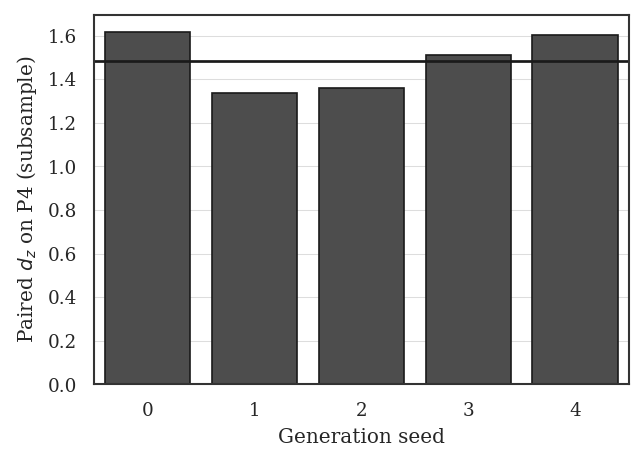


[done] diagnostics complete.


In [1]:
# ============================================================================
# 5_diagnostics.ipynb  —  Second-round review diagnostics (R3, R4, R6, R7)
# ----------------------------------------------------------------------------
# Independent, individually-toggleable blocks. Run AFTER notebooks 0-2 (needs
# data/with_override.parquet, data/perturbed.parquet, data/scored.parquet).
#
#   Block D (R7, OFFLINE) : recompute override descriptive stats + floor
#                           sensitivity from with_override.parquet, so the data
#                           section and appendix are consistent with the CURRENT
#                           proxy fit (fixes the stale tab_override_summary).
#   Block A (R3)          : diagnose why the proxy metric drops on P2 (removing
#                           qualitative clauses) -- claim-count / length artifact?
#   Block C (R4)          : sensitivity of the P4b construct test to the grade
#                           move magnitude (CONSTRUCT_NOTCH).
#   Block B (R6)          : run-to-run stability of the P4 effect across seeds.
#
# OUTPUT  results/tables/{tab_floor_sensitivity, tab_p2_metric_diagnosis,
#         tab_p4b_notch_sensitivity, tab_multiseed_p4} (+ figures)
# ============================================================================
import sys, os, json, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd

_HERE = Path.cwd()
_ROOT = _HERE if (_HERE / "src").exists() else _HERE.parent
sys.path.insert(0, str(_ROOT / "src"))
from common import (PROJECT_ROOT, DATA_DIR, RESULTS_DIR, FIGURES_DIR, TABLES_DIR,
                    load_env, set_grayscale_style, save_fig, save_table,
                    require_input, RANDOM_SEED)
import matplotlib.pyplot as plt
import seaborn as sns
set_grayscale_style()
np.random.seed(RANDOM_SEED)
warnings.filterwarnings("ignore")
from scipy.stats import wilcoxon, spearmanr

# ---- toggles ----------------------------------------------------------------
RUN_D_FLOOR = True        # R7: offline, no API
RUN_A_P2    = True        # R3: offline correlation + optional LLM claim-count
RUN_A_LLM   = True        #     the LLM part of R3 (claim-count decomposition)
RUN_C_P4B   = True        # R4: LLM
RUN_B_SEED  = True        # R6: LLM
MAX_WORKERS = 8

RATING_ORDER = ["D", "C", "CC", "CCC", "B", "BB", "BBB", "A", "AA", "AAA"]
idx = {g: i for i, g in enumerate(RATING_ORDER)}
def shift_grade(g, k):
    if g not in idx: return g
    return RATING_ORDER[max(0, min(len(RATING_ORDER) - 1, idx[g] + k))]
def tmap(fn, items):
    items = list(items)
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as ex:
        return list(ex.map(fn, items))

# LLM client + helpers are only needed by the non-offline blocks.
if RUN_A_LLM or RUN_C_P4B or RUN_B_SEED:
    cfg = load_env()
    from openai import OpenAI
    client = OpenAI(api_key=cfg["api_key"])
    JUDGE = cfg["strong"]; GEN = cfg["mid"]; EDIT = cfg["mid"]; FAITH = cfg["mid"]

    def judge_qual(rationale, rating, delta, show_grade=True, seed=None):
        gap = (f"Context: the agency rating is {int(delta):+d} notches vs the "
               f"quantitative profile; a good rationale presents a qualitative "
               f"justification whose direction matches this gap.")
        sysm = ("You are evaluating a credit rating rationale. Score five axes "
                "1-5: grade_accuracy, grade_rationale_consistency, "
                "qualitative_adequacy, factual_faithfulness, explainability. "
                "qualitative_adequacy: 5=clear & consistent with the gap's "
                "direction, 3=present but generic, 1=absent or contradicting.")
        gl = (f"Rating: {rating}\n" if show_grade else
              "Rating: [withheld — score the rationale's reasoning only]\n")
        kw = {} if seed is None else {"seed": seed}
        r = client.chat.completions.create(model=JUDGE, temperature=0.0,
            messages=[{"role": "system", "content": sysm},
                      {"role": "user", "content": f"{gap}\n{gl}Rationale:\n{rationale}\n\nReturn JSON with the five integer axes."}],
            response_format={"type": "json_object"}, **kw)
        return float(json.loads(r.choices[0].message.content).get("qualitative_adequacy", np.nan))

# ============================================================================
# BLOCK D (R7) — recompute override descriptive stats + floor sensitivity
# ============================================================================
if RUN_D_FLOOR:
    ov = pd.read_parquet(require_input(DATA_DIR / "with_override.parquet",
                                       hint="Run notebook 0 first."))
    n = len(ov)
    mad = float(np.median(np.abs(ov["delta"] - ov["delta"].median()))) * 1.4826
    outside = ((ov["y_rank"] < ov["lo"]) | (ov["y_rank"] > ov["hi"]))
    coverage = float((~outside).mean())
    rows = []
    for tau in [round(1.5 * mad, 2), 1.40, 1.45, 2.00]:
        cnt = int((outside & (ov["delta"].abs() >= tau)).sum())
        rows.append({"tau": tau, "overrides": cnt, "rate_pct": round(100 * cnt / n, 1)})
    floor = pd.DataFrame(rows).drop_duplicates("tau").sort_values("tau")
    save_table(floor, "tab_floor_sensitivity")
    summ = pd.DataFrame({"metric": ["n_rows", "n_firms", "residual_scale_mad",
                                     "band_coverage_80", "n_outside_band",
                                     "adopted_floor_1.5xMAD", "override_rows_adopted"],
                         "value": [n, ov["cik"].nunique() if "cik" in ov else np.nan,
                                   round(mad, 3), round(coverage, 3), int(outside.sum()),
                                   round(1.5 * mad, 2),
                                   int((outside & (ov["delta"].abs() >= round(1.5 * mad, 2))).sum())]})
    save_table(summ, "tab_override_summary")   # overwrites the stale one, consistently
    print("== R7: override descriptive stats (current fit) ==")
    print(summ.to_string(index=False)); print(floor.to_string(index=False))
    print("-> paste these into the data section (MAD, coverage, n_outside) and the "
          "appendix floor table; they now match the override count used in analysis.")

# ============================================================================
# BLOCK A (R3) — why does the proxy metric drop on P2?
# ============================================================================
if RUN_A_P2:
    s = pd.read_parquet(require_input(DATA_DIR / "scored.parquet", hint="Run notebook 2 first."))
    h = s[(s.judge_cond == "informed") & (s.condition == "gap_given")].copy()
    h["flen"] = h["rationale"].astype(str).str.len()
    p0 = h[h.pert == "P0"].set_index("case_id")
    p2 = h[h.pert == "P2"].set_index("case_id")
    j = p0[["faithfulness", "flen"]].join(p2[["faithfulness", "flen"]], lsuffix="_p0", rsuffix="_p2").dropna()
    j["d_faith"] = (j["faithfulness_p0"] - j["faithfulness_p2"]) * 5.0     # metric drop (x5)
    j["d_len"] = j["flen_p0"] - j["flen_p2"]                               # chars removed
    rho_len, p_len = spearmanr(j["d_faith"], j["d_len"])
    print("\n== R3: P2 proxy-metric diagnosis (offline) ==")
    print(f"mean metric drop on P2 (x5): {j['d_faith'].mean():.3f}")
    print(f"mean chars removed by P2    : {j['d_len'].mean():.0f}")
    print(f"corr(metric drop, chars removed): Spearman rho={rho_len:.3f} (p={p_len:.3g})")
    fig, ax = plt.subplots(figsize=(4.6, 3.2))
    ax.scatter(j["d_len"], j["d_faith"], s=14, color="#1a1a1a")
    ax.set_xlabel("Characters removed by P2 (P0 - P2)"); ax.set_ylabel("Proxy metric drop (x5)")
    save_fig(fig, "fig_p2_metric_diagnosis"); plt.show()

    diag = {"mean_metric_drop_x5": round(float(j["d_faith"].mean()), 3),
            "mean_chars_removed": round(float(j["d_len"].mean()), 1),
            "spearman_drop_vs_charsremoved": round(float(rho_len), 3),
            "spearman_p": round(float(p_len), 4)}

    if RUN_A_LLM:
        # Decompose: re-score P0 and P2 logging {entailed, total}. If `total`
        # (claim count) falls on P2 while the entailment RATE is ~stable, the
        # drop is a mechanical claim-count artifact, not a faithfulness change.
        pert = pd.read_parquet(DATA_DIR / "perturbed.parquet")
        w = pert[(pert.condition == "gap_given") & (pert.pert.isin(["P0", "P2"]))].to_dict("records")
        def faith_ct(rec):
            sysm = ("Return JSON {\"entailed\": int, \"total\": int}: of the "
                    "quantitative/factual claims in the rationale, how many are "
                    "entailed by the stated financial sector/profile.")
            try:
                r = client.chat.completions.create(model=FAITH, temperature=0.0,
                    messages=[{"role": "system", "content": sysm},
                              {"role": "user", "content": str(rec["rationale"])[:4000]}],
                    response_format={"type": "json_object"})
                o = json.loads(r.choices[0].message.content)
                return {"case_id": rec["case_id"], "pert": rec["pert"],
                        "entailed": int(o.get("entailed", 0)), "total": max(1, int(o.get("total", 1)))}
            except Exception:
                return {"case_id": rec["case_id"], "pert": rec["pert"], "entailed": np.nan, "total": np.nan}
        ct = pd.DataFrame(tmap(faith_ct, w))
        g = ct.groupby("pert").agg(mean_total=("total", "mean"),
                                   mean_ratio=("entailed", lambda x: np.nanmean(ct.loc[x.index, "entailed"] / ct.loc[x.index, "total"]))).reset_index()
        print("\nclaim-count decomposition (P0 vs P2):")
        print(g.to_string(index=False))
        diag["mean_total_P0"] = round(float(g[g.pert == "P0"]["mean_total"].iloc[0]), 2)
        diag["mean_total_P2"] = round(float(g[g.pert == "P2"]["mean_total"].iloc[0]), 2)
        diag["mean_ratio_P0"] = round(float(g[g.pert == "P0"]["mean_ratio"].iloc[0]), 3)
        diag["mean_ratio_P2"] = round(float(g[g.pert == "P2"]["mean_ratio"].iloc[0]), 3)
    save_table(pd.DataFrame([diag]), "tab_p2_metric_diagnosis")
    print("Interpretation guide: a large positive corr with chars-removed, and/or a "
          "drop in mean_total with a stable ratio, indicates the P2 'metric drop' is "
          "a claim-count/length artifact rather than a genuine faithfulness change.")

# ============================================================================
# BLOCK C (R4) — P4b grade-move magnitude sensitivity
# ============================================================================
if RUN_C_P4B:
    pert = pd.read_parquet(require_input(DATA_DIR / "perturbed.parquet", hint="Run notebook 1 first."))
    base = pert[pert.condition == "gap_given"]
    p0 = base[base.pert == "P0"][["case_id", "delta", "rating", "rationale"]].rename(
        columns={"rating": "rating0", "rationale": "rationale0"})
    p4 = base[base.pert == "P4"][["case_id", "delta", "rating", "rationale"]].rename(
        columns={"rating": "rating4", "rationale": "rationale4"})
    m = p0.merge(p4[["case_id", "rationale4"]], on="case_id")
    NOTCH_VALUES = [1, 2, 3]
    # judge P0 once (grade shown) for pairing
    def jp0(rec): return (rec["case_id"], judge_qual(rec["rationale0"], rec["rating0"], rec["delta"], True))
    p0score = dict(tmap(jp0, m.to_dict("records")))
    rows = []
    for notch in NOTCH_VALUES:
        def jp4b(rec):
            g = shift_grade(rec["rating0"], -int(np.sign(rec["delta"])) * notch)
            q_show = judge_qual(rec["rationale4"], g, rec["delta"], True)
            q_hide = judge_qual(rec["rationale4"], g, rec["delta"], False)
            return (rec["case_id"], q_show, q_hide)
        res = tmap(jp4b, m.to_dict("records"))   # each item: (case_id, q_shown, q_hidden)
        for view, ti in [("shown", 1), ("hidden", 2)]:
            drops = []
            for item in res:
                cid, q = item[0], item[ti]
                base = p0score.get(cid, np.nan)
                if not np.isnan(q) and not np.isnan(base):
                    drops.append(base - q)
            drops = np.array(drops)
            dz = drops.mean() / (drops.std(ddof=1) + 1e-9) if len(drops) > 1 else np.nan
            rows.append({"construct_notch": notch, "grade_view": view, "n": len(drops),
                         "judge_drop": round(float(drops.mean()), 3) if len(drops) else np.nan,
                         "d_z": round(float(dz), 3) if len(drops) > 1 else np.nan})
    tab = pd.DataFrame(rows)
    save_table(tab, "tab_p4b_notch_sensitivity")
    print("\n== R4: P4b sensitivity to grade-move magnitude ==")
    print(tab.to_string(index=False))
    fig, ax = plt.subplots(figsize=(4.6, 3.2))
    sns.barplot(data=tab, x="construct_notch", y="judge_drop", hue="grade_view",
                palette=["#1a1a1a", "#b3b3b3"], edgecolor="#1a1a1a", ax=ax)
    ax.set_xlabel("P4b grade move (notches)"); ax.set_ylabel("Judge drop vs P0"); ax.legend(frameon=False, fontsize=8)
    save_fig(fig, "fig_p4b_notch_sensitivity"); plt.show()

# ============================================================================
# BLOCK B (R6) — run-to-run stability of the P4 effect across seeds
# ============================================================================
if RUN_B_SEED:
    SEEDS = [0, 1, 2, 3, 4]
    K_CASES = 40
    GEN_TEMP = 0.2
    MDNA_BUDGET = 6000
    ov = pd.read_parquet(require_input(DATA_DIR / "with_override.parquet", hint="Run notebook 0 first."))
    sub = ov[ov["override"]].sample(n=min(K_CASES, int(ov["override"].sum())), random_state=RANDOM_SEED)

    def regen_p0(row, seed):
        mdna = str(row.get("mdna_text", ""))[:MDNA_BUDGET]
        sysm = ("You are a credit analyst. Produce a letter rating and a short "
                "rationale citing quantitative and qualitative factors (parent/"
                "group/government support, industry, governance).")
        user = (f"Financial sector: {row.get('Sector','NA')}.\n"
                f"The agency rating sits {int(row.delta):+d} notches versus the "
                f"quantitative stand-alone profile.\nRelevant MD&A excerpt:\n{mdna}\n\n"
                f"Return JSON: {{\"rating\": <letter>, \"rationale\": <text>}}")
        r = client.chat.completions.create(model=GEN, temperature=GEN_TEMP, seed=seed,
            messages=[{"role": "system", "content": sysm}, {"role": "user", "content": user}],
            response_format={"type": "json_object"})
        return json.loads(r.choices[0].message.content)

    def flip_p4(rationale, seed):
        r = client.chat.completions.create(model=EDIT, temperature=0.0, seed=seed,
            messages=[{"role": "system", "content": "You edit a credit rationale as instructed. Return only the edited text."},
                      {"role": "user", "content": "Reverse the polarity of the qualitative support argument "
                       "(support -> drag, or drag -> support) while keeping the same grade and surface form.\n\nRATIONALE:\n" + str(rationale)}])
        return r.choices[0].message.content.strip()

    seed_rows = []
    for seed in SEEDS:
        def one(row):
            try:
                o = regen_p0(row, seed); g, t = o.get("rating"), o.get("rationale")
                t4 = flip_p4(t, seed)
                q0 = judge_qual(t, g, row.delta, True, seed=seed)
                q4 = judge_qual(t4, g, row.delta, True, seed=seed)
                return q0 - q4
            except Exception:
                return np.nan
        drops = np.array([d for d in tmap(one, [r for _, r in sub.iterrows()]) if d is not None and not np.isnan(d)])
        if len(drops) > 1:
            dz = drops.mean() / (drops.std(ddof=1) + 1e-9)
            seed_rows.append({"seed": seed, "n": len(drops),
                              "p4_judge_drop": round(float(drops.mean()), 3), "d_z": round(float(dz), 3)})
    st = pd.DataFrame(seed_rows)
    save_table(st, "tab_multiseed_p4")
    print("\n== R6: P4 effect stability across seeds ==")
    print(st.to_string(index=False))
    print(f"d_z across seeds: mean={st['d_z'].mean():.3f}, sd={st['d_z'].std(ddof=1):.3f}, "
          f"range=[{st['d_z'].min():.3f}, {st['d_z'].max():.3f}]")
    fig, ax = plt.subplots(figsize=(4.6, 3.2))
    sns.barplot(data=st, x="seed", y="d_z", color="#4d4d4d", edgecolor="#1a1a1a", ax=ax)
    ax.axhline(st["d_z"].mean(), color="#1a1a1a", linewidth=1.3)
    ax.set_xlabel("Generation seed"); ax.set_ylabel("Paired $d_z$ on P4 (subsample)")
    save_fig(fig, "fig_multiseed_p4"); plt.show()

print("\n[done] diagnostics complete.")
